<a href="https://colab.research.google.com/github/najmunnaharhira/Advanced-Matrix_Operation-/blob/main/banglish_detectors_experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Why AI Text Detectors Struggle with Banglish: experiment

Companion notebook for the blog post. Run the cells from top to bottom.

**Before you start:** go to **Runtime > Change runtime type** and choose **T4 GPU**. It still works on CPU, just more slowly.

You need `samples.csv` with these columns: `id, text, label, pair_id, generator, topic`. The `label` column must be `human` or `ai`. Rows whose `id` starts with `example` are skipped.

## 1. Install and import

In [ ]:
!pip install -q transformers pandas scikit-learn matplotlib

import math
import matplotlib.pyplot as plt
import pandas as pd
import torch
from sklearn.metrics import accuracy_score
from transformers import AutoModelForCausalLM, AutoTokenizer, pipeline

DEVICE = 0 if torch.cuda.is_available() else -1
print("GPU" if DEVICE == 0 else "CPU (slower, still fine)")

GPU


## 2. Upload samples.csv
A file picker opens when you run this cell. Choose your `samples.csv`.

In [ ]:
from google.colab import files
uploaded = files.upload()
CSV_NAME = list(uploaded)[0]  # Colab renames repeat uploads, e.g. "samples (1).csv"
print("Using", CSV_NAME)

Saving samples.csv to samples.csv
Using samples.csv


## 3. Load and check the data

In [ ]:
df = pd.read_csv(CSV_NAME, dtype=str, keep_default_na=False)
df = df[~df["id"].str.startswith("example")]
df["text"] = df["text"].str.strip()
df["label"] = df["label"].str.strip().str.lower()
df = df[df["text"] != ""].drop_duplicates("text").reset_index(drop=True)

assert len(df) > 0, ("No samples found. samples.csv only has the example rows. "
                     "Add your own human and AI texts, then upload it again.")
for lab in ["human", "ai"]:
    assert (df["label"] == lab).any(), f"No rows labelled {lab!r}. You need both human and ai rows."

bad = df[~df["label"].isin(["human", "ai"])]
assert bad.empty, f"These rows need label human or ai:\n{bad[['id', 'label']]}"

print(df["label"].value_counts())
print(df.groupby("label")["generator"].value_counts())
df.sample(min(5, len(df)), random_state=0)

label
human    100
ai       100
Name: count, dtype: int64
label  generator
ai     chatgpt       50
       gemini        50
human  human        100
Name: count, dtype: int64


,id,text,label,pair_id,generator,topic
18,h019,Very nice sutagula and onek good quality. Same...,human,,human,"product review (2021, 5 star)"
170,c021,Product er battery backup description er motoi...,ai,,chatgpt,product review
107,g008,"Pathao rider eto kach theke gari nilo, ajk pur...",ai,,gemini,product review
98,h099,Same as pic......sudhu akta box dile valo hoto,human,,human,"product review (2022, 5 star)"
177,c028,Product review gula purchase decision e help k...,ai,,chatgpt,product review


## 4. Figure 1: how tokenizers split Banglish
Change the three sentences if you like. Keep the meaning the same across all three.

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

xlm-roberta-base   English         15  ['▁I', '▁won', "'", 't', '▁go', '▁to', '▁class', '▁tomorrow', ',', '▁I', "'", 'm']
xlm-roberta-base   Bangla script   13  ['▁আমি', '▁কাল', '▁ক্ল', 'াস', 'ে', '▁যা', 'ব', '▁না', ',', '▁খুব', '▁ক্ল', 'ান্ত']
xlm-roberta-base   Banglish        11  ['▁ami', '▁kal', '▁class', '▁e', '▁ja', 'bo', '▁na', ',', '▁too', '▁tired', '.']


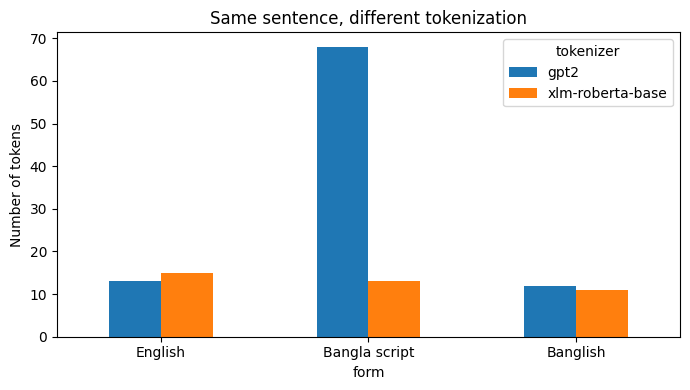

tokenizer,gpt2,xlm-roberta-base
form,,
Bangla script,68,13
Banglish,12,11
English,13,15


In [ ]:
SENTENCES = {
    "English": "I won't go to class tomorrow, I'm too tired.",
    "Bangla script": "আমি কাল ক্লাসে যাব না, খুব ক্লান্ত।",
    "Banglish": "ami kal class e jabo na, too tired.",
}
rows = []
for name in ["gpt2", "xlm-roberta-base"]:
    tok = AutoTokenizer.from_pretrained(name)
    for form, text in SENTENCES.items():
        pieces = tok.tokenize(text)
        rows.append({"tokenizer": name, "form": form, "tokens": len(pieces)})
        print(f"{name:18} {form:14} {len(pieces):3}  {pieces[:12]}")

tokens = pd.DataFrame(rows).pivot(index="form", columns="tokenizer", values="tokens")
ax = tokens.loc[list(SENTENCES)].plot.bar(rot=0, figsize=(7, 4))
ax.set_ylabel("Number of tokens")
ax.set_title("Same sentence, different tokenization")
plt.tight_layout(); plt.savefig("fig1_tokens.png", dpi=200); plt.show()
tokens

## 5. Run the trained classifiers
These are open detectors from Hugging Face. The first run downloads them, which takes a minute or two.

In [ ]:
CLASSIFIERS = {
    "ChatGPT-RoBERTa (HC3)": "Hello-SimpleAI/chatgpt-detector-roberta",
    "OpenAI GPT-2 detector": "openai-community/roberta-base-openai-detector",
}
# Label names each model uses for "AI". Check the printed labels below.
AI_LABELS = {"chatgpt", "fake", "label_1", "ai"}

texts = df["text"].tolist()
for name, model_id in CLASSIFIERS.items():
    clf = pipeline("text-classification", model=model_id, device=DEVICE, truncation=True)
    out = clf(texts, batch_size=16)
    print(name, "returns labels:", sorted({o["label"] for o in out}))
    df[name] = ["ai" if o["label"].lower() in AI_LABELS else "human" for o in out]
    # Confidence that the text is AI, used for Figure 3
    df[name + " p(ai)"] = [o["score"] if o["label"].lower() in AI_LABELS else 1 - o["score"]
                           for o in out]

config.json:   0%|          | 0.00/858 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  499MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/391 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

OpenAI GPT-2 detector returns labels: ['Fake', 'Real']


## 6. Run the perplexity detector (zero-shot)
A small multilingual language model scores how "surprising" each text is. Lower perplexity counts as AI. The threshold is the median, which is simple and easy to explain in the blog.

In [ ]:
PPL_MODEL = "bigscience/bloom-560m"
tok = AutoTokenizer.from_pretrained(PPL_MODEL)
lm = AutoModelForCausalLM.from_pretrained(PPL_MODEL).eval()
if DEVICE == 0:
    lm = lm.cuda()

ppl = []
for text in texts:
    enc = tok(text, return_tensors="pt", truncation=True, max_length=256)
    enc = {k: v.to(lm.device) for k, v in enc.items()}
    with torch.no_grad():
        ppl.append(math.exp(lm(**enc, labels=enc["input_ids"]).loss.item()))
df["perplexity"] = ppl

threshold = df["perplexity"].median()
df["Perplexity (BLOOM-560m)"] = ["ai" if p < threshold else "human" for p in ppl]
print(df.groupby("label")["perplexity"].describe().round(1))

config.json:   0%|          | 0.00/693 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/222 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 14.5MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/293 [00:00<?, ?it/s]

       count     mean      std    min     25%     50%      75%       max
label                                                                   
ai     100.0  10876.8  16884.8  567.5  3729.3  6064.3  11525.6  115669.6
human  100.0   7191.6   9383.5   90.3  1960.6  3654.9   8239.7   63625.8


## 7. Figure 2: results for each detector

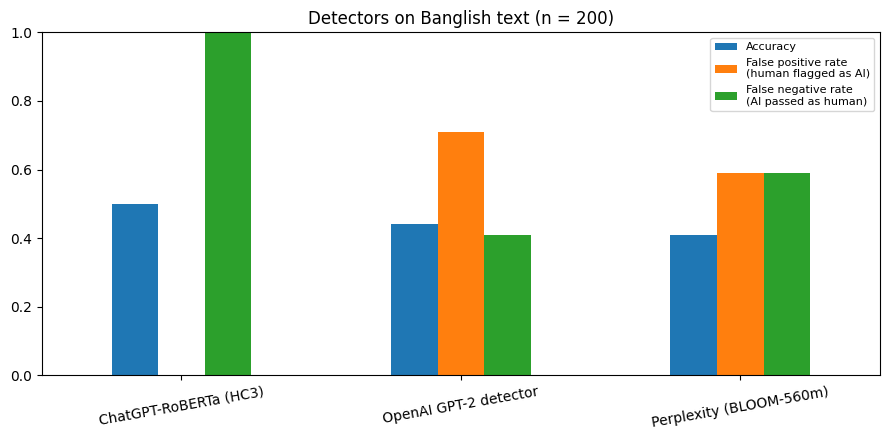

,Accuracy,False positive rate\n(human flagged as AI),False negative rate\n(AI passed as human)
ChatGPT-RoBERTa (HC3),0.50,0.00,1.00
OpenAI GPT-2 detector,0.44,0.71,0.41
Perplexity (BLOOM-560m),0.41,0.59,0.59


Share of AI texts that passed as human, by generator:


,ChatGPT-RoBERTa (HC3),OpenAI GPT-2 detector,Perplexity (BLOOM-560m)
generator,,,
chatgpt,1.0,0.44,0.76
gemini,1.0,0.38,0.42


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [ ]:
DETECTORS = list(CLASSIFIERS) + ["Perplexity (BLOOM-560m)"]
y = df["label"]

def rates(pred):
    human, ai = pred[y == "human"], pred[y == "ai"]
    return {
        "Accuracy": accuracy_score(y, pred),
        "False positive rate\n(human flagged as AI)": (human == "ai").mean(),
        "False negative rate\n(AI passed as human)": (ai == "human").mean(),
    }

results = pd.DataFrame({d: rates(df[d]) for d in DETECTORS}).T
ax = results.plot.bar(rot=10, figsize=(9, 4.5), ylim=(0, 1))
ax.set_title(f"Detectors on Banglish text (n = {len(df)})")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("fig2_detectors.png", dpi=200); plt.show()
display(results.round(3))

ai_rows = df[df["label"] == "ai"]
by_gen = pd.DataFrame({d: ai_rows.groupby("generator")[d].apply(lambda s: (s == "human").mean())
                       for d in DETECTORS})
print("Share of AI texts that passed as human, by generator:")
by_gen.round(3)

## 8. Figure 3: where the detectors went wrong
These are the most confident mistakes from the first classifier. Pick 3 or 4 for the blog.

In [ ]:
main = DETECTORS[0]
wrong = df[df[main] != df["label"]].copy()
wrong["confidence"] = (wrong[main + " p(ai)"] - 0.5).abs() * 2
cols = ["text", "label", main, main + " p(ai)", "generator"]
wrong.sort_values("confidence", ascending=False)[cols].head(10)

,text,label,ChatGPT-RoBERTa (HC3),ChatGPT-RoBERTa (HC3) p(ai),generator
140,Delivery date chilo last week e kintu order ek...,ai,human,0.000268,gemini
142,Daraz e 11.11 sale er jonno je product gular d...,ai,human,0.000272,gemini
157,"Seller er packaging dekhe impressed hoisi, box...",ai,human,0.000273,chatgpt
139,Headphone er bam pashe sound thik ashe but dan...,ai,human,0.000275,gemini
124,Earbuds er left side ta kaj korche na. 7 days ...,ai,human,0.000277,gemini
182,Product er color real e aro sundor lagse.,ai,human,0.000278,chatgpt
166,Refund er update na ashay abar support e knock...,ai,human,0.000281,chatgpt
112,Laptop er display ajk sudden kore black hoye g...,ai,human,0.000281,gemini
161,Product er quality dekhe mone hocche price ta ...,ai,human,0.000284,chatgpt
195,"Product er price reasonable chilo, quality o m...",ai,human,0.000284,chatgpt


## 9. Save and download everything

In [ ]:
df.to_csv("predictions.csv", index=False)
results.to_csv("results.csv")
by_gen.to_csv("results_by_generator.csv")
for f in ["fig1_tokens.png", "fig2_detectors.png", "predictions.csv", "results.csv", "results_by_generator.csv"]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>